<div style="background: linear-gradient(120deg, #3b1e54 0%, #8a2a6b 62%, #d6336c 100%); color: #ffffff; padding: 30px 34px; border-radius: 14px; margin: 4px 0 10px 0;">
<div style="font-size: 0.8em; letter-spacing: 0.16em; text-transform: uppercase; opacity: 0.85;">Statistical Methods · GSSI · Lecture 3 · 17/11</div>
<div style="font-size: 2.7em; font-weight: 800; line-height: 1.1; margin: 10px 0 8px 0;">Monte Carlo &amp; Information</div>
<div style="font-size: 1.15em; opacity: 0.95;">Make randomness work for you, then ask what the data are really telling you.</div>
</div>

**Reading** · G. Benato, *Statistical Methods for Astroparticle Physics* (GSSI lecture notes), chapters 3-5.

**In this lecture**

1. [Pseudo-random number generators](#s1)
2. [Generating non-uniform numbers](#s2)
3. [Numerical integration with Monte Carlo](#s3)
4. [Markov chain Monte Carlo](#s4)
5. [Information](#s5)
6. [Which question are you asking?](#s6)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler
from scipy import stats

# --- house style: one palette for every figure ------------------------------------
PLUM, FUCHSIA, TEAL, AMBER, GREY = "#3b1e54", "#d6336c", "#0b7285", "#e8890c", "#6b7280"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110,
    "axes.prop_cycle": cycler(color=[FUCHSIA, PLUM, TEAL, AMBER]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": "#2a1a3a", "text.color": "#2a1a3a",
    "xtick.color": GREY, "ytick.color": GREY, "lines.linewidth": 2.0,
    "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 10,
})
rng = np.random.default_rng(2026)   # fixed seed: every run gives the same figures

---
## 1. Pseudo-random number generators <a id="s1"></a>

A **pseudo-random number generator** is an algorithm that produces a sequence of numbers distributed according to a given PDF. A good one must satisfy four requirements:

- **Independence:** each extraction is independent of the previous ones, $f(x_i | x_{i-m}) = f(x_i)\ \forall\, i, m$.
- **Same PDF:** all extractions follow the same distribution, $f(x_i) = f(x_j)\ \forall\, i, j$.
- **Period:** after $p$ extractions the sequence repeats itself, $x_{i+p} = x_i$. We want $p$ as large as possible.
- **Reproducibility:** we can initialize the sequence, usually with a **seed**. Essential for debugging.

Most generators produce numbers uniform in $[0, 1)$. A uniform number can be remapped to any interval $[a, b)$ with $x \to x' = a + x\,(b - a)$.

<div style="border-left: 6px solid #0b7285; background: #e5f3f6; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**↗ Extra: a generator in four lines**

A classic recipe (the one behind C's `lrand48`) is the *linear congruential generator*: $x_{i+1} = (a\,x_i + c) \bmod m$, with $m = 2^{48}$, $a = 25\,214\,903\,917$ and $c = 11$. Four lines are enough to see the requirements at work.

</div>

In [2]:
def lcg(seed, n, a=25_214_903_917, c=11, m=2**48):
    x, out = seed, []
    for _ in range(n):
        x = (a * x + c) % m
        out.append(x / m)                        # map to [0, 1)
    return np.array(out)

u = lcg(seed=42, n=100_000)
print("first numbers:", u[:4].round(4), "| mean:", u.mean().round(3), "(uniform: 0.5)")
print("same seed, same sequence:", np.array_equal(lcg(42, 4), u[:4]))

first numbers: [0.0038 0.7016 0.9208 0.5307] | mean: 0.5 (uniform: 0.5)
same seed, same sequence: True


---
## 2. Generating non-uniform numbers <a id="s2"></a>

### Inverse-transform method (1D)

**Goal:** generate random numbers following a PDF $f(x)$. The cumulative $F(x)$ maps $x$ into $[0, 1)$, so we go backwards:

1. generate $r$ uniformly in $[0, 1)$,
2. invert the cumulative: $x = F^{-1}(r)$.

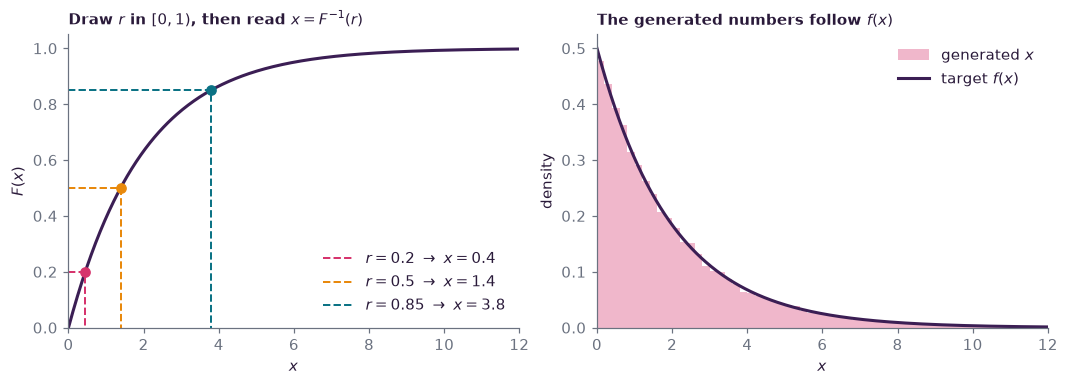

In [3]:
lam = 0.5
F = lambda x: 1 - np.exp(-lam * x)
F_inv = lambda r: -np.log(1 - r) / lam
x = np.linspace(0, 12, 400)
samples = F_inv(rng.random(50_000))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.6, 3.4), constrained_layout=True)
a1.plot(x, F(x), color=PLUM)
for r, color in zip([0.2, 0.5, 0.85], [FUCHSIA, AMBER, TEAL]):
    xr = F_inv(r)
    a1.plot([0, xr, xr], [r, r, 0], color=color, ls="--", lw=1.3, label=rf"$r = {r}\ \to\ x = {xr:.1f}$")
    a1.plot(xr, r, "o", color=color)
a1.set(xlabel="$x$", ylabel="$F(x)$", xlim=(0, 12), ylim=(0, 1.05))
a1.legend(frameon=False, loc="lower right")
a1.set_title(r"Draw $r$ in $[0,1)$, then read $x = F^{-1}(r)$", loc="left", fontsize=10)

a2.hist(samples, bins=60, range=(0, 12), density=True, color=FUCHSIA, alpha=0.35, label="generated $x$")
a2.plot(x, lam * np.exp(-lam * x), color=PLUM, label="target $f(x)$")
a2.set(xlabel="$x$", ylabel="density", xlim=(0, 12))
a2.legend(frameon=False)
a2.set_title("The generated numbers follow $f(x)$", loc="left", fontsize=10)
plt.show()

<div style="border-left: 6px solid #e8890c; background: #fff3dc; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**▲ Watch out**

The cumulative must be **invertible** (analytically or numerically). With logarithms we may run into numerical problems, and in more than one dimension it becomes difficult.

</div>

### Acceptance-rejection method (hit or miss)

Assume a PDF $f(x)$ defined in $[x_1, x_2]$, and that we know its maximum $m = \max\{f(x),\ x \in [x_1, x_2]\}$.

1. Generate a uniform number $x$ in $[x_1, x_2]$.
2. Generate a uniform number $r$ in $[0, m]$.
3. If $f(x) > r$, **accept** $x$; otherwise restart.
4. Populate a histogram with the accepted values: for many generated points it approximates $f(x)$.

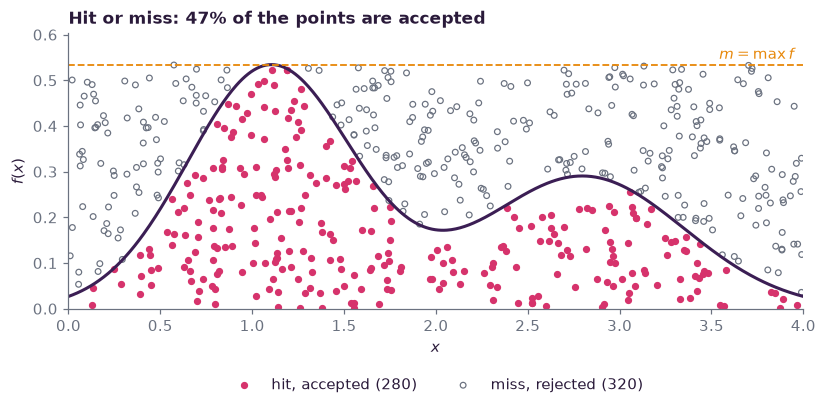

In [4]:
x1, x2 = 0.0, 4.0
f = lambda x: 0.6 * stats.norm(1.1, 0.45).pdf(x) + 0.4 * stats.norm(2.8, 0.55).pdf(x)
xs = np.linspace(x1, x2, 500)
m = f(xs).max()
n = 600
xr, rr = rng.uniform(x1, x2, n), rng.uniform(0, m, n)
hit = rr < f(xr)

fig, ax = plt.subplots(figsize=(7.4, 3.6), constrained_layout=True)
ax.plot(xs, f(xs), color=PLUM, lw=2)
ax.scatter(xr[hit], rr[hit], s=14, color=FUCHSIA, label=f"hit, accepted ({hit.sum()})")
ax.scatter(xr[~hit], rr[~hit], s=14, facecolor="none", edgecolor=GREY, lw=0.8, label=f"miss, rejected ({(~hit).sum()})")
ax.axhline(m, color=AMBER, ls="--", lw=1.2)
ax.text(x2 - 0.05, m + 0.012, r"$m = \max f$", ha="right", color=AMBER)
ax.set(xlim=(x1, x2), ylim=(0, m * 1.13), xlabel="$x$", ylabel="$f(x)$")
ax.set_title(f"Hit or miss: {hit.mean():.0%} of the points are accepted", loc="left")
ax.legend(frameon=False, loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.2))
plt.show()

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Acceptance-rejection**

**Efficiency:** the fraction of accepted points is

$$\varepsilon = \frac{\int_{x_1}^{x_2} f(x)\,dx}{(x_2 - x_1)\cdot m}$$

so the method is **inefficient if $f(x)$ is strongly peaked**. It works well if $f(x)$ is cheap to compute, and it gives only an approximated (binned) version of $f(x)$. It applies to multi-dimensional cases too, but the higher the dimension, the lower the efficiency: the *curse of dimensionality*.

</div>

<div style="border-left: 6px solid #3b1e54; background: #f0e9f7; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**✎ Exercise**

How fast does the efficiency collapse with the dimension? Find out with points in a hypercube and a hypersphere.

- [Acceptance-rejection method](../exercises/02_monte_carlo/ex02_acceptance_rejection.ipynb)

</div>

---
## 3. Numerical integration with Monte Carlo <a id="s3"></a>

The acceptance-rejection method also estimates an integral, from the fraction of accepted points $k$ over the number $n$ of generated ones:

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Monte Carlo integration**

$$I = \int_{x_1}^{x_2} f(x)\,dx \simeq (x_2 - x_1)\cdot m\cdot\frac{k}{n} \qquad\qquad \sigma_{\hat I} = \sqrt{\frac{\hat I\,\big[(x_2 - x_1)\,m - \hat I\,\big]}{n}}$$

The uncertainty does **not** depend on the dimensionality: that is what makes Monte Carlo advantageous for integrals of high-dimensional PDFs. The catch can be finding the maximum of $f(x)$.

</div>

A quick check on an integral we know, $\int_0^{\pi}\sin x\,dx = 2$, with the box $[0, \pi] \times [0, 1]$:

In [5]:
n = 200_000
x1, x2, m = 0.0, np.pi, 1.0
x, r = rng.uniform(x1, x2, n), rng.uniform(0, m, n)
k = np.sum(r < np.sin(x))                       # points below the curve

box_area = (x2 - x1) * m
I = box_area * k / n
sigma_I = np.sqrt(I * (box_area - I) / n)
print(f"I = {I:.4f} ± {sigma_I:.4f}   (exact value: 2)")

I = 2.0033 ± 0.0034   (exact value: 2)


---
## 4. Markov chain Monte Carlo <a id="s4"></a>

A sequence of random variables $x_0, \dots, x_n$ is a **Markov chain** if each extraction depends only on the immediately previous one:

$$f(x_{n+1}\,|\,x_0, \dots, x_n) = f(x_{n+1}\,|\,x_n)$$

Some distributions can be sampled much more efficiently by producing correlated numbers like this. It works in any dimension.

### The Metropolis-Hastings algorithm

We want to sample a PDF $f(\vec{x})$. The recipe uses a *proposal function* $q(\vec{x}\,|\,\vec{x}_0)$ (also called the stepping function), the PDF of the "test point" $\vec{x}$ given the current point $\vec{x}_0$:

1. Pick a point $\vec{x}_0$ uniformly distributed in the (finite) sample space $\Omega$.
2. Evaluate $f(\vec{x}_0)$.
3. Generate a "test point" $\vec{x}$ according to the proposal $q(\vec{x}\,|\,\vec{x}_0)$.
4. Evaluate $f(\vec{x})$.
5. Generate a uniform number $u \in [0, 1)$.
6. If
$$\frac{f(\vec{x})\;q(\vec{x}_0\,|\,\vec{x})}{f(\vec{x}_0)\;q(\vec{x}\,|\,\vec{x}_0)} > u$$
   accept $\vec{x}$ and set $\vec{x}_1 = \vec{x}$. Otherwise go back to step 3.

If the proposal is symmetric, $q(\vec{x}\,|\,\vec{x}_0) = q(\vec{x}_0\,|\,\vec{x})$, the ratio simplifies to $f(\vec{x})/f(\vec{x}_0)$: a move to a higher point is always accepted, while a lower point is accepted with a small but non-zero probability.

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ How to read it**

The algorithm does **not** find the maximum: it *maps* the distribution, favouring the more populated regions. Think of a drunk man walking in a potential well.

- The proposal function must **not change** during the run.
- In higher dimensions a single chain can stay stuck in one region (for instance one of several modes): run multiple chains simultaneously.

</div>

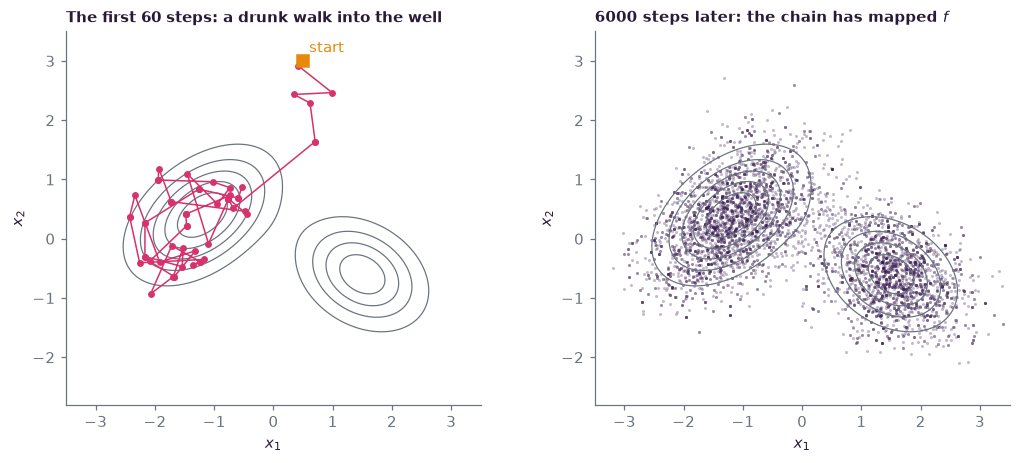

In [6]:
def target(p):                                    # un-normalized 2D PDF: two Gaussian blobs
    p = np.atleast_2d(p)
    return (0.6 * stats.multivariate_normal([-1.2, 0.4], [[0.5, 0.2], [0.2, 0.4]]).pdf(p)
            + 0.4 * stats.multivariate_normal([1.5, -0.6], [[0.4, -0.1], [-0.1, 0.3]]).pdf(p))

def metropolis_hastings(f, x0, n_steps, step, rng):
    chain, x = [np.asarray(x0, float)], np.asarray(x0, float)
    for _ in range(n_steps):
        x_new = rng.normal(x, step)               # symmetric proposal: the q ratio is 1
        if f(x_new) / f(x) > rng.random():  # accept: move; reject: stay where we are
            x = x_new
        chain.append(x)
    return np.array(chain)

chain = metropolis_hastings(target, x0=(0.5, 3.0), n_steps=6000, step=0.5, rng=rng)
g = np.linspace(-3.5, 3.5, 250)
X, Y = np.meshgrid(g, g)
Z = target(np.dstack([X, Y]).reshape(-1, 2)).reshape(X.shape)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.6, 4.1), constrained_layout=True)
for ax in (a1, a2):
    ax.contour(X, Y, Z, levels=6, colors=GREY, linewidths=0.8)
    ax.set(xlabel="$x_1$", ylabel="$x_2$", aspect="equal", xlim=(-3.5, 3.5), ylim=(-2.8, 3.5))
a1.plot(*chain[:60].T, "-o", color=FUCHSIA, ms=3.5, lw=1)
a1.plot(*chain[0], "s", color=AMBER, ms=8)
a1.text(0.6, 3.15, "start", color=AMBER)
a1.set_title("The first 60 steps: a drunk walk into the well", loc="left", fontsize=10)
a2.scatter(*chain[500:].T, s=4, alpha=0.3, color=PLUM, lw=0)
a2.set_title("6000 steps later: the chain has mapped $f$", loc="left", fontsize=10)
plt.show()

<div style="border-left: 6px solid #e8890c; background: #fff3dc; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**▲ Rejected steps count**

Strictly, to sample $f$ **exactly**, a rejected proposal must be counted: the chain repeats the current point, one entry per proposal. If we collect only the *accepted* points, as in the steps above and in the exercise, regions where proposals are accepted more often get over-represented. In the exercise you collect only accepted points: pay attention to what that does to the distribution of $x_i$ and of $x_i - x_{i-1}$.

</div>

<div style="border-left: 6px solid #3b1e54; background: #f0e9f7; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**✎ Exercise**

Compare a plain Gaussian generator with a Metropolis-Hastings one: how correlated are consecutive numbers?

- [Random number correlation](../exercises/02_monte_carlo/ex03_random_number_correlation.ipynb)

</div>

---
## 5. Information <a id="s5"></a>

When we perform an experiment we collect a huge amount of data that we need to clean and reduce in order to make a statement on the quantity we are interested in. In CUORE we have $\sim 200$ TB of raw data, but our publications just report the half-life of an isotope; CMS and ATLAS have PBs of data, but just measured the Higgs mass and cross section. We need a method to select the **useful information**. But first we need to define the requirements for what we call *information*. It should:

- **increase** with the number of observations,
- be **conditional** on what we want to learn from the experiment: data irrelevant to the hypothesis under test should contain no information,
- be such that the **greater** the information, the **better** the precision of the experiment.

### Likelihood

Take a (real) random variable $\vec{x}$ with PDF $f(\vec{x}\,|\,\vec\theta)$, where $\vec\theta$ is a set of (real) parameters. The set of allowed values of $\vec{x}$ is $\Omega_{\vec\theta}$, which might depend on $\vec\theta$. Suppose we have $n$ measurements $\vec{x}_1, \dots, \vec{x}_n$. The joint PDF on the measured points is

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Likelihood**

$$P(\vec{x}\,|\,\vec\theta) = \prod_{i=1}^{n} f(\vec{x}_i\,|\,\vec\theta) = \mathcal{L}(\vec{x}\,|\,\vec\theta) = \mathcal{L}(\vec\theta)$$

It is **no longer a PDF**, because the $\vec{x}_i$ are fixed by the measurement: it is a function of $\vec\theta$, not a PDF in $\vec\theta$.

</div>

### Fisher information

Assume that (1) $\Omega_{\vec\theta}$ does not depend on $\vec\theta$, and (2) $\mathcal{L}$ is regular enough so that $\frac{\partial^2}{\partial\theta_i\,\partial\theta_j}$ and $\int d\vec{x}$ commute. Then

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Fisher information**

$$I_F(\theta) = E\!\left[\left(\frac{\partial \ln\mathcal{L}(\theta)}{\partial\theta}\right)^{2}\right] = \int_\Omega \left(\frac{\partial\ln\mathcal{L}}{\partial\theta}\right)^{2}\mathcal{L}\,d\vec{x} = -E\!\left[\frac{\partial^2}{\partial\theta^2}\ln\mathcal{L}\right]$$

If $\vec\theta$ has dimension $K$, $I_F$ is a $K \times K$ matrix: $\;[I_F(\vec\theta)]_{ij} = \int_\Omega \frac{\partial\ln\mathcal{L}}{\partial\theta_i}\frac{\partial\ln\mathcal{L}}{\partial\theta_j}\,\mathcal{L}\,d\vec{x} = -E\!\left[\frac{\partial^2}{\partial\theta_i\,\partial\theta_j}\ln\mathcal{L}\right]$.

It is **additive**: $I_N(\vec\theta) = N\,I_1(\vec\theta)$.

</div>

### Statistic and sufficiency

A **statistic** is any new random variable $t = t(\vec{x}_1, \dots, \vec{x}_n)$. For example, the average is a statistic. A statistic $t$ is **sufficient** for $\vec\theta$ if the conditional density $f(\vec{x}\,|\,t)$ is independent of $\vec\theta$. Then there is as much information about $\vec\theta$ in $t$ as in the original data $\vec{x}$, and no other function of the data can give any further information about $\vec\theta$. If $t$ is sufficient, any strictly monotonic function of $t$ is sufficient too.

The set $t = \vec{x}$ is sufficient, since it carries all the initial information. But it provides no data reduction, so it is useless. If $t$ is sufficient, the likelihood factorizes:

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Sufficient statistic**

$$\mathcal{L}(\vec{x}\,|\,\vec\theta) = g(t, \vec\theta)\;h(\vec{x}) \qquad\qquad g(t, \vec\theta) \propto A(t\,|\,\vec\theta)$$

where $h(\vec{x})$ does not depend on $\vec\theta$ and $A(t|\vec\theta)$ is the conditional probability of $t$ given $\vec\theta$. In general, for any statistic, $\;I_t(\vec\theta) \le I_{\vec{x}}(\vec\theta)$, with equality if and only if $t$ is sufficient: the information provided by a sufficient statistic is the same as that of the original sample $\vec{x}$.

</div>

---
## 6. Which question are you asking? <a id="s6"></a>

Suppose we collect data $\vec{x}$ distributed with a PDF $f(\vec{x}\,|\,\vec\theta)$, and we want to make a statement on one parameter $\theta$ (out of the vector $\vec\theta$). There are four different questions we can ask, and each one requires dedicated statistical and computational methods. Understanding the relation between **question** and **method** is fundamental, and will save you a lot of time (trust me!).

So far the language has been vague on purpose. To be specific we have to choose an approach:

- **Frequentist:** the true value of the parameter $\theta$ is fixed but unknown. We cannot associate a PDF to $\theta$, only to the data $\vec{x}$.
- **Bayesian:** probability is a *degree of belief*, so it applies to a wider range of elements: random variables, (true) parameters of a model, and hypotheses.

| | Frequentist | Bayesian | Method |
|:--|:--|:--|:--|
| **Point estimation** | What is our best estimate for the fixed unknown parameter, i.e. the value $\hat\theta$ closest to the true one? | What is the most probable value of $\theta$? | Find the $\hat\theta$ that maximizes $\mathcal{L}$ (or the posterior): a **minimizer** algorithm, e.g. a gradient follower |
| **Interval estimation** | What interval contains the true value with a predefined probability (e.g. 68%)? Repeat the measurement 100 times: you get 100 different intervals, and the true value is inside 68 of them | What interval of the PDF of $\theta$, $f(\theta)$, contains a given amount of probability (e.g. 68%)? | Study the tails of $\mathcal{L}$ or of the posterior $P(\theta\,\vert\,\vec{x})$. F: study all the combinations of $\theta$ giving $\vec{x}$, with **toy Monte Carlo**. B: **map** the posterior with **Markov chain Monte Carlo** |
| **Goodness of fit** | Does my model provide a suitable description of the data, or is there any indication that it should be modified? What is the probability that a random fluctuation gives a worse fit? | *No sense*: we cannot compare one hypothesis with $N$ unknown ones | An analytical method (e.g. $\chi^2$) plus look-up tables, or **toy Monte Carlo** |
| **Hypothesis testing** | Which of two (or more) alternative hypotheses is true? Assuming $H_0$ is true, what is the probability that the data fake $H_1$ (and vice versa)? In practice: compare the signal strength with the probability of a similarly strong background fluctuation | What is the ratio of the probabilities of $H_0$ and $H_1$? | F: **toy Monte Carlo** + a method to compare the validity of the alternative hypotheses. B: a **multi-dimensional integrator** |

Two pictures to remember. A **minimizer** follows the gradient up to the maximum of the likelihood: it answers *where is the best value?* A **mapper** samples the whole distribution: it answers *how far can the parameters wander and still describe the data?*

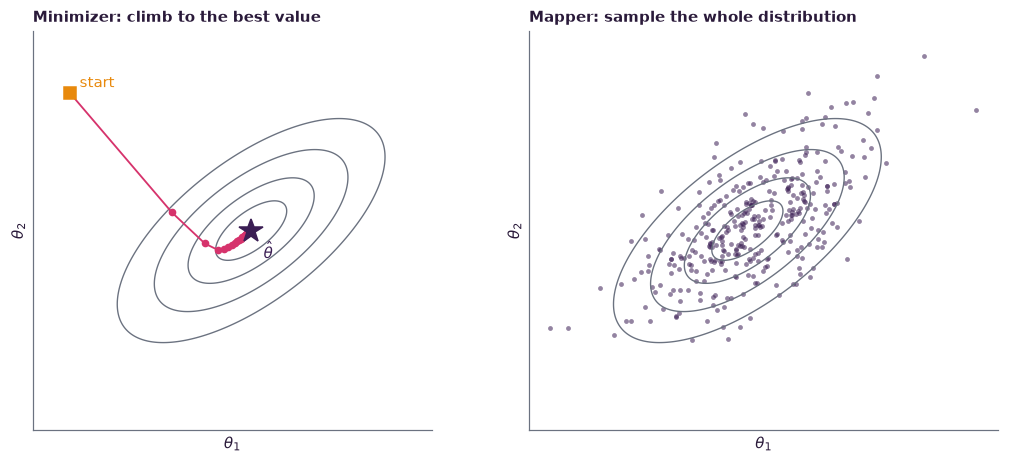

In [7]:
g = np.linspace(-3.2, 3.2, 300)
X, Y = np.meshgrid(g, g)
mu_t = np.array([0.3, 0.0])
C = np.array([[1.0, 0.55], [0.55, 0.7]])
Ci = np.linalg.inv(C)
Z = np.exp(-0.5 * np.einsum("...i,ij,...j", np.dstack([X, Y]) - mu_t, Ci, np.dstack([X, Y]) - mu_t))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.6, 4.1), constrained_layout=True)
for ax in (a1, a2):
    ax.contour(X, Y, Z, levels=[0.1, 0.3, 0.6, 0.85], colors=GREY, linewidths=0.9)
    ax.set(xlabel=r"$\theta_1$", ylabel=r"$\theta_2$", aspect="equal", xticks=[], yticks=[])

# minimizer: gradient ascent on ln L, from a far-away start
p = np.array([-2.6, 2.2])
path = [p]
for _ in range(22):
    p = p - 0.2 * Ci @ (p - mu_t)                  # step along the gradient of ln L
    path.append(p)
path = np.array(path)
a1.plot(*path.T, "-o", color=FUCHSIA, ms=4, lw=1.2)
a1.plot(*path[0], "s", color=AMBER, ms=8)
a1.plot(*mu_t, "*", color=PLUM, ms=16)
a1.text(*(path[0] + [0.15, 0.1]), "start", color=AMBER)
a1.text(mu_t[0] + 0.2, mu_t[1] - 0.45, r"$\hat{\theta}$", color=PLUM, fontweight="bold")
a1.set_title("Minimizer: climb to the best value", loc="left", fontsize=10)

# mapper: sample the whole distribution
pts = rng.multivariate_normal(mu_t, C, 350)
a2.scatter(*pts.T, s=10, color=PLUM, alpha=0.55, lw=0)
a2.set_title("Mapper: sample the whole distribution", loc="left", fontsize=10)
plt.show()

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**★ What to remember**

- **A pseudo-random generator** is a deterministic algorithm that fakes randomness well enough: independent, same PDF, long period, reproducible through its seed.
- **Non-uniform numbers:** invert the cumulative when you can, hit-or-miss when you can't. Hit-or-miss loses efficiency in high dimension.
- **Monte Carlo integration** has an uncertainty that does not depend on the dimension.
- **Metropolis-Hastings** builds a Markov chain that *maps* a distribution. Count the rejected steps, or the map will be biased.
- **The likelihood** is a function of the parameters and not a PDF; **Fisher information** measures how much a measurement tells you; a **sufficient statistic** loses nothing.
- **Four questions, four methods:** point estimation, interval estimation, goodness of fit, hypothesis testing.

</div>